In [1]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests

import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import date
import numpy as np
import datetime

pd.options.display.max_rows = 999
pd.options.display.max_columns = 999

In [2]:
df_k9 = pd.read_csv("../H3K9me3-zhuojie-regions/data/zhuojie_c1_avglogfc.csv")
df_k9 = df_k9.rename(columns={"avg_logFC": "logFC_k9"})
df_k9.shape

(91, 5)

In [3]:
df_k9.head(1)

,tissue,cell_type,logFC_k9,num_up_peaks,num_down_peaks
0,brainCB,brainCB-GC_ExN,-1.565036,2,273


In [4]:
df_genes = pd.read_csv("../../../RNA/GSEA/data/ssgsea_scores.csv")
df_genes.shape

(6237, 388)

In [5]:
df_long = df_genes.melt(
    id_vars=["GO_ID", "Description"],
    var_name="celltype_age",
    value_name="score"
)
# 2️⃣ 拆分 cell type 和 age
df_long[["cell_type", "age"]] = df_long["celltype_age"].str.split("__", expand=True)

df_final = df_long.pivot_table(
    index=["GO_ID", "Description", "cell_type"],
    columns="age",
    values="score"
).reset_index()

# 4️⃣ 重命名列
df_final = df_final.rename(columns={
    "3m": "3m_score",
    "27m": "27m_score"
})


df_final.columns.name = None
df_final.head()

,GO_ID,Description,cell_type,27m_score,3m_score
0,GO:0000002,mitochondrial genome maintenance,BAT-ASPC,0.243963,0.245340
1,GO:0000002,mitochondrial genome maintenance,BAT-Adipocyte,0.283406,0.289495
2,GO:0000002,mitochondrial genome maintenance,BAT-B_cell,0.285775,0.303186
3,GO:0000002,mitochondrial genome maintenance,BAT-Brown_adipocyte,0.291837,0.301348
4,GO:0000002,mitochondrial genome maintenance,BAT-MSC,0.266660,0.251787


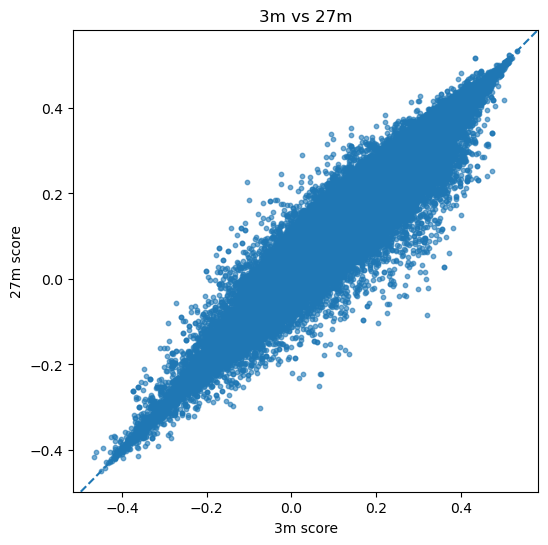

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(df_final["3m_score"], df_final["27m_score"], s=10, alpha=0.6)

plt.xlabel("3m score")
plt.ylabel("27m score")
plt.title("3m vs 27m")

plt.axline((0, 0), slope=1, linestyle="--")  # y=x 参考线

plt.show()

In [8]:
df_genes = df_final
df_genes["gene"] = df_genes["Description"]
df_genes["logFC"] = df_genes["3m_score"]
df_genes["FDR"] = 1
df_genes.head(1)

,GO_ID,Description,cell_type,27m_score,3m_score,gene,logFC,FDR
0,GO:0000002,mitochondrial genome maintenance,BAT-ASPC,0.243963,0.24534,mitochondrial genome maintenance,0.24534,1


In [21]:
results = []

for gene, df_g in df_genes.groupby("Description"):

    df_m = (
        df_g
        .merge(df_k9, on=["cell_type"], how="inner")
        .dropna(subset=["3m_score", "logFC_k9"])
    )

    # 至少需要 10 个点
    if df_m.shape[0] < 10:
        continue

    # Pearson
    r_p, p_p = pearsonr(df_m["3m_score"], df_m["logFC_k9"])

    # Spearman
    r_s, p_s = spearmanr(df_m["3m_score"], df_m["logFC_k9"])

    results.append({
        "gene": gene, #,
        # "Description":df_g["Description"],
        "n_points": df_m.shape[0],
        "pearson_r": r_p,
        "pearson_p": p_p,
        "spearman_r": r_s,
        "spearman_p": p_s
    })



In [22]:

df_corr = pd.DataFrame(results)
df_corr["pearson_fdr"] = multipletests(df_corr["pearson_p"],  method="fdr_bh")[1]
df_corr["spearman_fdr"] = multipletests(df_corr["spearman_p"],  method="fdr_bh")[1]
df_corr = df_corr.sort_values("pearson_fdr")
df_corr.to_csv("data/H3K9me3_ssGSEA_corr.csv", index=False)
df_corr.shape

(6237, 8)

In [23]:
df_corr.head()

,gene,n_points,pearson_r,pearson_p,spearman_r,spearman_p,pearson_fdr,spearman_fdr
2795,negative regulation of organelle assembly,91,-0.540127,3.282907e-08,-0.613967,9.691835e-11,0.000086,6.044798e-07
1075,cytoplasmic sequestering of transcription factor,91,-0.536851,4.118853e-08,-0.565950,5.032406e-09,0.000086,9.488215e-06
824,cellular response to gamma radiation,91,-0.538382,3.705732e-08,-0.605558,2.030380e-10,0.000086,6.331739e-07
1513,gastric acid secretion,91,0.513687,1.915395e-07,0.535866,4.407463e-08,0.000299,1.619922e-05
1913,lens fiber cell development,91,-0.507314,2.866437e-07,-0.515273,1.730264e-07,0.000358,2.997682e-05


#### plot #####

In [ ]:
pos_corr_f = df_corr[(df_corr['spearman_r'] > 0) & (df_corr['spearman_fdr'] < 0.05)]
neg_corr_f = df_corr[(df_corr['spearman_r'] < 0) & (df_corr['spearman_fdr'] < 0.05)]

# Order genes by spearman_fdr ascending (most significant first)
pos_genes_ordered = pos_corr_f.sort_values('spearman_fdr', ascending=True)['gene'].tolist()
neg_genes_ordered = neg_corr_f.sort_values('spearman_fdr', ascending=True)['gene'].tolist()

In [28]:
df_corr[df_corr.spearman_fdr<0.05].to_csv("ssgeas.csv",index=False)

In [33]:
df_corr[df_corr["gene"]=="meiotic nuclear division"]
df_corr[df_corr["gene"]=="mitotic nuclear division"]

,gene,n_points,pearson_r,pearson_p,spearman_r,spearman_p,pearson_fdr,spearman_fdr
2269,mitotic nuclear division,91,-0.123535,0.243358,-0.289059,0.005454,0.409558,0.017417


In [24]:


# Cell type order: low → high logFC_k9
ct_order = df_k9.sort_values('logFC_k9', ascending=True)['cell_type'].tolist()
logfc_k9_vals = df_k9.set_index('cell_type').loc[ct_order, 'logFC_k9'].values

# Build wide matrices
df_pos_wide = df_genes[df_genes['gene'].isin(pos_genes_ordered)].pivot_table(
    index='gene', columns='cell_type', values='logFC', aggfunc='mean'
).reindex(index=pos_genes_ordered, columns=ct_order)

df_neg_wide = df_genes[df_genes['gene'].isin(neg_genes_ordered)].pivot_table(
    index='gene', columns='cell_type', values='logFC', aggfunc='mean'
).reindex(index=neg_genes_ordered, columns=ct_order)

df_pos_sig = df_genes[df_genes['gene'].isin(pos_genes_ordered)].pivot_table(
    index='gene', columns='cell_type', values='FDR', aggfunc='mean'
).reindex(index=pos_genes_ordered, columns=ct_order)

df_neg_sig = df_genes[df_genes['gene'].isin(neg_genes_ordered)].pivot_table(
    index='gene', columns='cell_type', values='FDR', aggfunc='mean'
).reindex(index=neg_genes_ordered, columns=ct_order)

print(f"Pos: {len(pos_genes_ordered)} genes | Neg: {len(neg_genes_ordered)} genes")
print(f"Top 5 pos genes by FDR: {pos_genes_ordered[:5]}")
print(f"Top 5 neg genes by FDR: {neg_genes_ordered[:5]}")


Pos: 375 genes | Neg: 2664 genes
Top 5 pos genes by FDR: ['long-chain fatty-acyl-CoA metabolic process', 'gastric acid secretion', 'sleep', 'regulation of circadian sleep/wake cycle, sleep', 'circadian sleep/wake cycle, sleep']
Top 5 neg genes by FDR: ['negative regulation of organelle assembly', 'cellular response to gamma radiation', 'cytoplasmic sequestering of transcription factor', 'retrograde vesicle-mediated transport, Golgi to endoplasmic reticulum', 'lens development in camera-type eye']


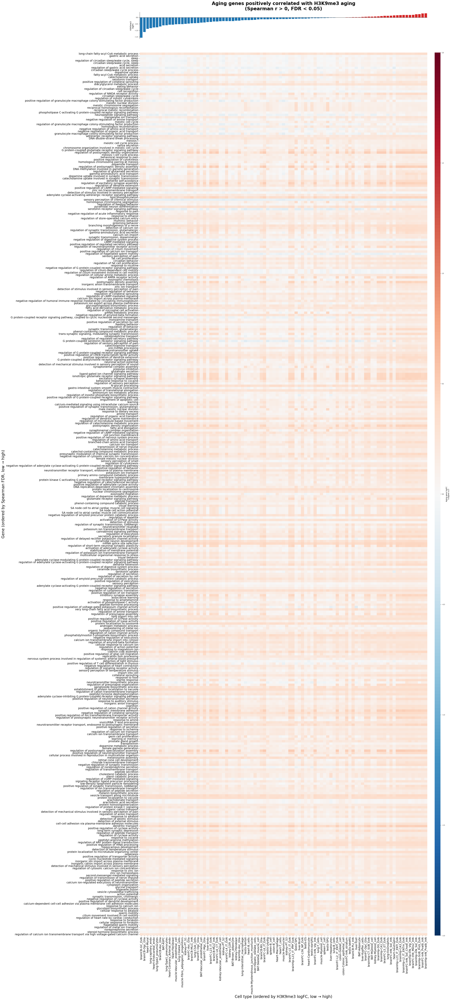

In [25]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np

vmax = 2.0
bar_colors = ['#D62728' if v > 0 else '#1F77B4' for v in logfc_k9_vals]

def make_full_figure(wide_df, sig_df, genes_ordered, ct_order, logfc_k9_vals,
                     bar_colors, title, ylabel, row_height=0.22, star_fontsize=5):

    n_genes = len(genes_ordered)
    n_ct = len(ct_order)
    fig_height = max(10, n_genes * row_height + 4)

    fig = plt.figure(figsize=(28, fig_height))

    # ✅ 关键：2列 layout，右边给 colorbar
    gs = gridspec.GridSpec(
        2, 2,
        height_ratios=[2.5, n_genes * row_height],
        width_ratios=[50, 1],
        hspace=0.03,
        wspace=0.05
    )

    # ======================
    # 🔵 Bar plot（左上）
    # ======================
    ax_bar = fig.add_subplot(gs[0, 0])

    ax_bar.bar(range(n_ct), logfc_k9_vals,
               color=bar_colors, width=0.8, linewidth=0)

    ax_bar.axhline(0, color='black', linewidth=0.8)
    ax_bar.set_xlim(-0.5, n_ct - 0.5)

    ax_bar.set_xticks([])
    ax_bar.set_ylabel('H3K9me3\nlogFC', fontsize=10)
    ax_bar.tick_params(axis='y', labelsize=8)

    ax_bar.spines['top'].set_visible(False)
    ax_bar.spines['right'].set_visible(False)
    ax_bar.spines['bottom'].set_visible(False)

    ax_bar.set_title(title, fontsize=24, fontweight='bold', pad=10)

    # ======================
    # 🔴 Heatmap（左下）
    # ======================
    ax_heat = fig.add_subplot(gs[1, 0])

    # colorbar 单独轴
    cbar_ax = fig.add_subplot(gs[1, 1])

    mask = wide_df.isna()

    hm = sns.heatmap(
        wide_df.clip(-vmax, vmax),
        mask=mask,
        cmap='RdBu_r',
        center=0,
        vmin=-vmax,
        vmax=vmax,
        ax=ax_heat,
        linewidths=0,
        cbar=True,
        cbar_ax=cbar_ax,   # ✅ 关键
        xticklabels=True,
        yticklabels=True,
    )

    ax_heat.set_facecolor('#D8D8D8')

    # ======================
    # ⭐ 标注显著性
    # ======================
    for i, gene in enumerate(genes_ordered):
        for j, ct in enumerate(ct_order):
            if ct not in sig_df.columns:
                continue

            fdr_val = sig_df.loc[gene, ct]

            if not np.isnan(fdr_val) and fdr_val < 0.05:
                ax_heat.text(
                    j + 0.5, i + 0.5, '*',
                    ha='center', va='center',
                    fontsize=star_fontsize,
                    color='black',
                    fontweight='bold'
                )

    # ======================
    # 🔧 axis 设置
    # ======================
    ax_heat.set_xlabel(
        'Cell type (ordered by H3K9me3 logFC, low → high)',
        fontsize=20
    )
    ax_heat.set_ylabel(ylabel, fontsize=20)

    ax_heat.tick_params(axis='x', labelsize=14, rotation=90)
    ax_heat.tick_params(axis='y', labelsize=14, rotation=0)

    # ======================
    # 🎯 colorbar 美化
    # ======================
    cbar = hm.collections[0].colorbar
    cbar.set_label('Aging gene logFC\n(clipped ±2)', fontsize=9)
    cbar.ax.tick_params(labelsize=7)

    return fig


# ======================
# 🚀 Figure 1: Positive
# ======================

fig1 = make_full_figure(
    df_pos_wide,
    df_pos_sig,
    pos_genes_ordered,
    ct_order,
    logfc_k9_vals,
    bar_colors,
    title='Aging genes positively correlated with H3K9me3 aging\n(Spearman r > 0, FDR < 0.05)',
    ylabel='Gene (ordered by Spearman FDR, low → high)',
)

fig1.show()


# ======================
# 🚀 Figure 2: Negative
# ======================

fig2 = make_full_figure(
    df_neg_wide,
    df_neg_sig,
    neg_genes_ordered,
    ct_order,
    logfc_k9_vals,
    bar_colors,
    title='Aging genes negatively correlated with H3K9me3 aging\n(Spearman r < 0, FDR < 0.05)',
    ylabel='Gene (ordered by Spearman FDR, low → high)',
)

fig2.show()